<a href="https://colab.research.google.com/github/Taniya1701/CSL701-CS06_Machine-Learning-Lab/blob/main/Experiments%20and%20Mini-Project/ML_Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name : Taniya Anil Bhise

Batch : CS01


Roll Number : CS06



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv('/content/palmerpenguins_extended.csv')

print(df.head())
print(df.shape)
print(df.columns)

  species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Biscoe            53.4           17.8              219.0   
1  Adelie  Biscoe            49.3           18.1              245.0   
2  Adelie  Biscoe            55.7           16.6              226.0   
3  Adelie  Biscoe            38.0           15.6              221.0   
4  Adelie  Biscoe            60.7           17.9              177.0   

   body_mass_g     sex  diet life_stage health_metrics  year  
0       5687.0  female  fish      adult     overweight  2021  
1       6811.0  female  fish      adult     overweight  2021  
2       5388.0  female  fish      adult     overweight  2021  
3       6262.0  female  fish      adult     overweight  2021  
4       4811.0  female  fish   juvenile     overweight  2021  
(3430, 11)
Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex', 'diet', 'life_stage',
       'health_metrics', 'year'],
      dtype='ob

# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [5]:
print(df.columns.tolist())

df = df.rename(columns={
    'bill_length_mm': 'culmen_length_mm',
    'bill_depth_mm': 'culmen_depth_mm'
})

features = [
    'culmen_length_mm',
    'culmen_depth_mm',
    'flipper_length_mm',
    'body_mass_g'
]

df = df.dropna(subset=features + ['species'])

X = df[features]
y = LabelEncoder().fit_transform(df['species'])

print("Features:")
print(X.head())

print("Target:")
print(y[:5])

['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'diet', 'life_stage', 'health_metrics', 'year']
Features:
   culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g
0              53.4             17.8              219.0       5687.0
1              49.3             18.1              245.0       6811.0
2              55.7             16.6              226.0       5388.0
3              38.0             15.6              221.0       6262.0
4              60.7             17.9              177.0       4811.0
Target:
[0 0 0 0 0]


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (2744, 4)
Testing data: (686, 4)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [7]:
cart = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

cart.fit(X_train, y_train)

y_pred_cart = cart.predict(X_test)

print("CART model trained successfully")
print("Predictions:", y_pred_cart)

CART model trained successfully
Predictions: [2 2 0 0 2 2 1 0 0 0 2 1 0 0 1 2 1 0 0 1 2 1 1 0 0 0 2 0 0 0 0 0 0 2 1 2 0
 0 2 2 0 0 1 1 2 0 0 1 1 0 0 1 1 0 2 2 0 2 1 1 0 2 1 0 2 2 0 1 1 0 2 0 1 0
 0 1 0 1 0 1 0 0 2 0 2 2 1 2 1 1 1 2 1 0 2 2 0 2 0 1 0 1 0 0 2 2 0 2 1 2 2
 2 0 1 2 1 0 2 1 2 2 1 2 1 0 0 1 0 0 0 0 0 0 1 0 2 0 0 1 1 2 1 0 0 2 0 0 2
 2 2 0 2 0 0 0 2 2 1 2 1 0 0 1 0 0 0 0 1 0 2 2 0 1 1 2 1 1 0 0 2 2 0 0 2 0
 2 1 0 2 2 2 0 1 2 2 0 0 1 0 2 2 1 0 2 2 0 0 2 1 2 0 2 0 0 2 0 0 2 0 0 1 0
 0 0 2 0 2 0 2 0 0 2 2 2 1 0 2 2 0 0 1 1 2 2 2 0 1 0 2 1 2 1 1 1 0 0 1 0 2
 0 2 0 2 1 1 0 0 0 1 2 2 0 0 2 0 1 0 2 1 0 0 0 2 0 2 2 2 2 2 0 2 1 2 0 1 2
 1 2 2 0 2 0 0 2 2 2 0 0 1 1 0 1 1 1 0 1 0 2 2 2 0 1 2 2 0 1 1 0 2 0 1 2 0
 2 1 0 2 2 0 1 1 0 1 2 0 1 2 0 2 0 2 2 2 2 1 2 2 1 2 1 2 0 2 1 1 0 2 0 2 1
 2 0 1 2 1 2 0 1 2 2 2 0 1 1 0 2 2 0 0 1 2 1 2 2 0 2 0 1 1 1 0 2 1 0 2 2 2
 2 2 0 0 2 2 2 0 1 2 0 1 0 0 1 0 2 0 2 2 0 2 2 2 1 2 0 1 1 1 0 0 1 2 0 1 2
 2 0 2 2 0 0 0 0 0 1 1 0 2 2 2 0 0 1 0 2 2 2 0 0 2 0 1 

# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

In [8]:

print("CART Accuracy:", accuracy_score(y_test, y_pred_cart))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_cart))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_cart))

CART Accuracy: 0.4518950437317784

Confusion Matrix:
[[155  64  93]
 [ 48  33  44]
 [ 76  51 122]]

Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.50      0.52       312
           1       0.22      0.26      0.24       125
           2       0.47      0.49      0.48       249

    accuracy                           0.45       686
   macro avg       0.42      0.42      0.42       686
weighted avg       0.46      0.45      0.46       686



# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


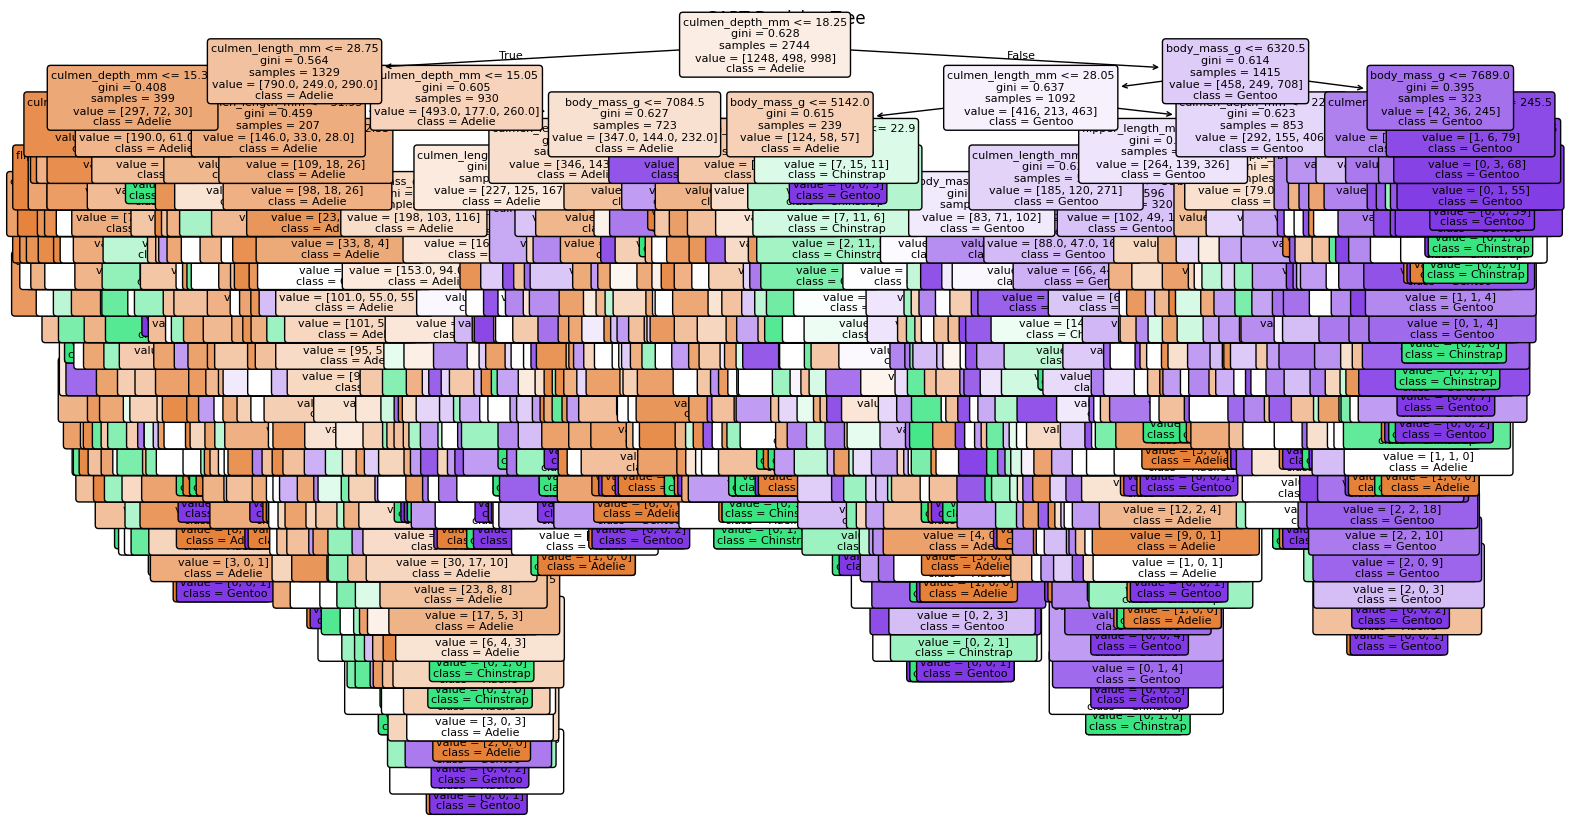

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


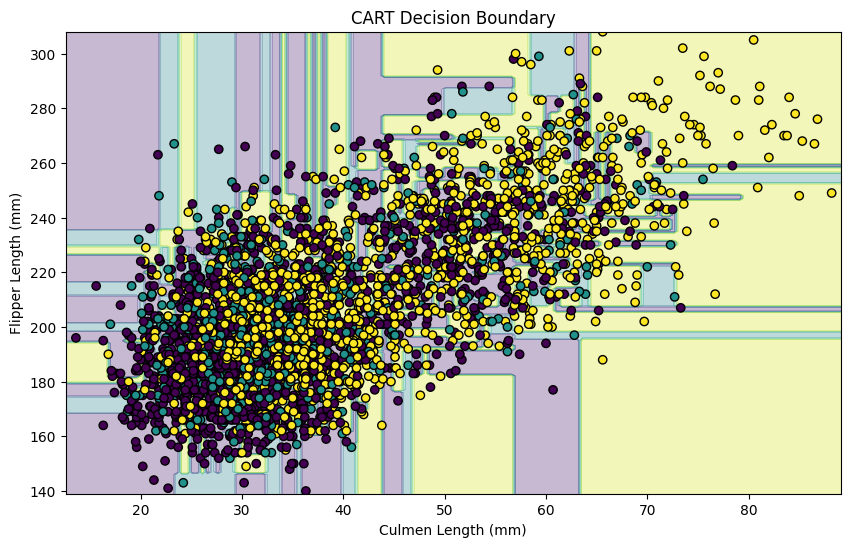

In [10]:
plt.figure(figsize=(18, 10))

plot_tree(
    cart,
    feature_names=features,
    class_names=LabelEncoder().fit(df['species']).classes_,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("CART Decision Tree")
plt.show()

X_2d = df[['culmen_length_mm', 'flipper_length_mm']]
y_2d = LabelEncoder().fit_transform(df['species'])

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d, y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

cart_2d = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

cart_2d.fit(X2_train, y2_train)

x_min, x_max = X_2d.iloc[:, 0].min() - 1, X_2d.iloc[:, 0].max() + 1
y_min, y_max = X_2d.iloc[:, 1].min() - 1, X_2d.iloc[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.5),
    np.arange(y_min, y_max, 1)
)

Z = cart_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
plt.scatter(
    X_2d.iloc[:, 0],
    X_2d.iloc[:, 1],
    c=y_2d,
    edgecolors='black',
    cmap='viridis'
)

plt.xlabel('Culmen Length (mm)')
plt.ylabel('Flipper Length (mm)')
plt.title('CART Decision Boundary')
plt.show()

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


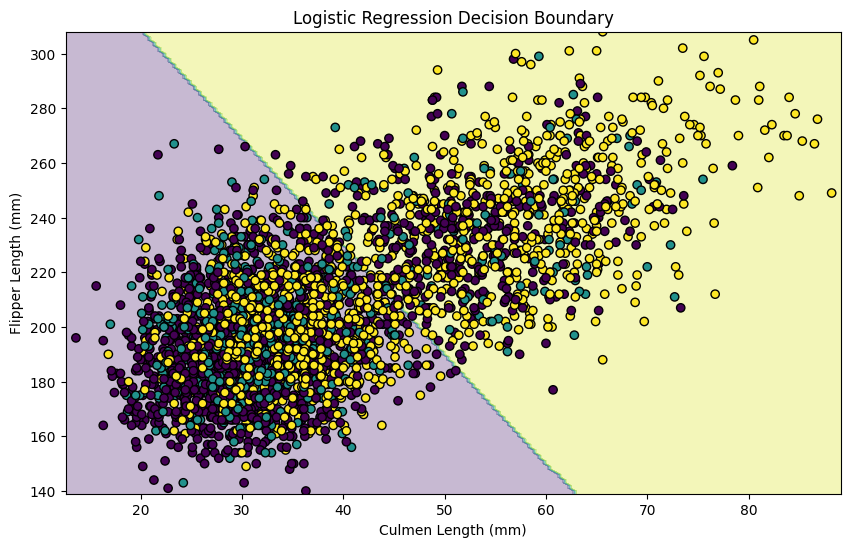

In [11]:
logistic = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

logistic.fit(X2_train, y2_train)

y_pred_logistic = logistic.predict(X2_test)

Z_logistic = logistic.predict(np.c_[xx.ravel(), yy.ravel()])
Z_logistic = Z_logistic.reshape(xx.shape)

plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z_logistic, alpha=0.3, cmap='viridis')
plt.scatter(
    X_2d.iloc[:, 0],
    X_2d.iloc[:, 1],
    c=y_2d,
    edgecolors='black',
    cmap='viridis'
)

plt.xlabel('Culmen Length (mm)')
plt.ylabel('Flipper Length (mm)')
plt.title('Logistic Regression Decision Boundary')
plt.show()

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


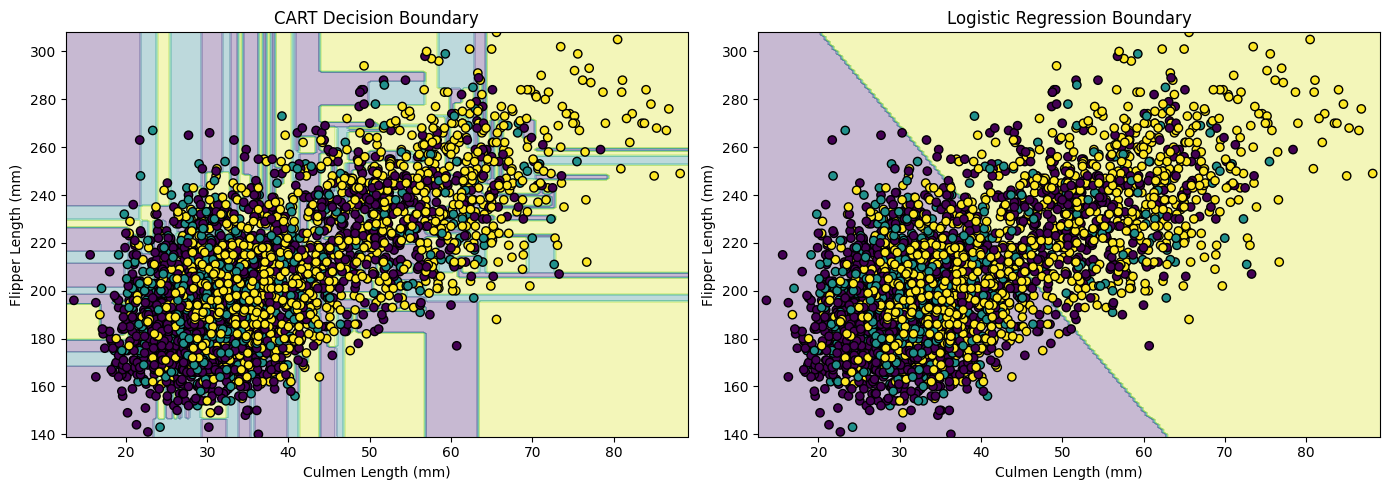

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].contourf(xx, yy, cart_2d.predict(
    np.c_[xx.ravel(), yy.ravel()]
).reshape(xx.shape), alpha=0.3, cmap='viridis')

axes[0].scatter(
    X_2d.iloc[:, 0], X_2d.iloc[:, 1],
    c=y_2d, edgecolors='black', cmap='viridis'
)

axes[0].set_title('CART Decision Boundary')
axes[0].set_xlabel('Culmen Length (mm)')
axes[0].set_ylabel('Flipper Length (mm)')

axes[1].contourf(xx, yy, logistic.predict(
    np.c_[xx.ravel(), yy.ravel()]
).reshape(xx.shape), alpha=0.3, cmap='viridis')

axes[1].scatter(
    X_2d.iloc[:, 0], X_2d.iloc[:, 1],
    c=y_2d, edgecolors='black', cmap='viridis'
)

axes[1].set_title('Logistic Regression Boundary')
axes[1].set_xlabel('Culmen Length (mm)')
axes[1].set_ylabel('Flipper Length (mm)')

plt.tight_layout()
plt.show()

# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

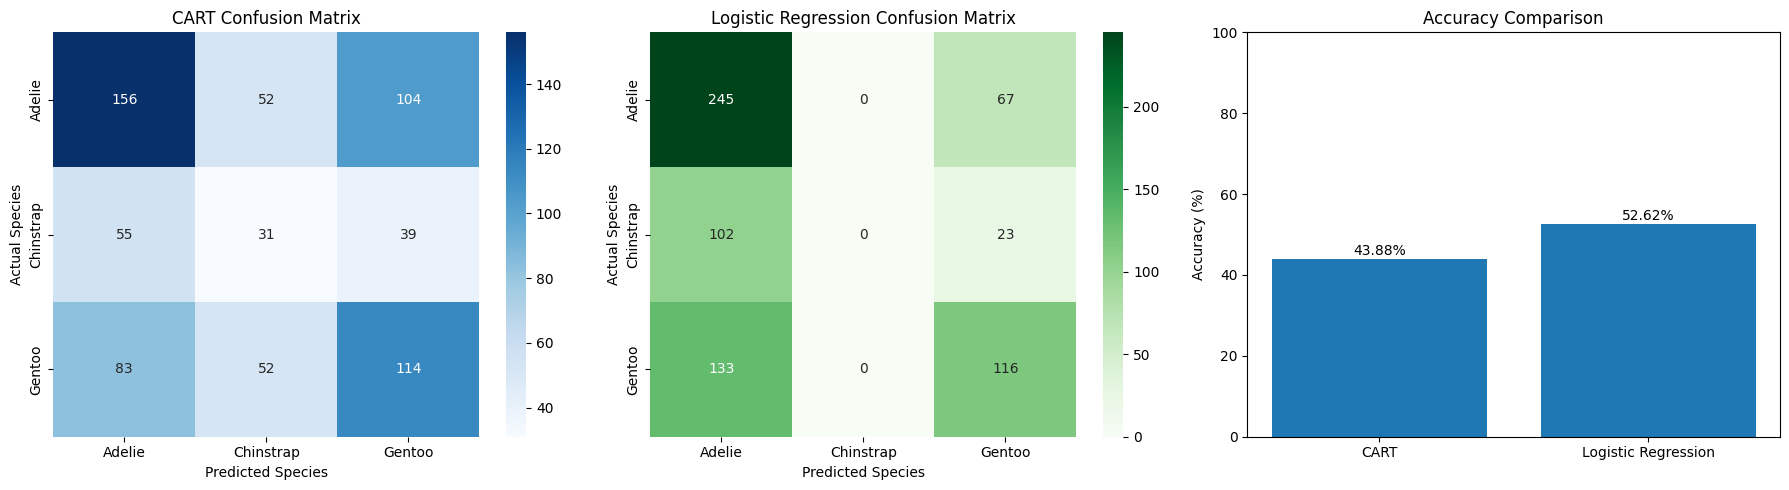

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix

# Predictions
y_pred_cart = cart_2d.predict(X2_test)
y_pred_logistic = logistic.predict(X2_test)

# Accuracy
cart_acc = accuracy_score(y2_test, y_pred_cart)
log_acc = accuracy_score(y2_test, y_pred_logistic)

# Class names
class_names = LabelEncoder().fit(df['species']).classes_

# Confusion matrices
cm_cart = confusion_matrix(y2_test, y_pred_cart)
cm_log = confusion_matrix(y2_test, y_pred_logistic)

# Create visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# CART Confusion Matrix
sns.heatmap(cm_cart, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names, ax=axes[0])

axes[0].set_title('CART Confusion Matrix')
axes[0].set_xlabel('Predicted Species')
axes[0].set_ylabel('Actual Species')

# Logistic Regression Confusion Matrix
sns.heatmap(cm_log, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names,
            yticklabels=class_names, ax=axes[1])

axes[1].set_title('Logistic Regression Confusion Matrix')
axes[1].set_xlabel('Predicted Species')
axes[1].set_ylabel('Actual Species')

# Accuracy Comparison
models = ['CART', 'Logistic Regression']
accuracies = [cart_acc * 100, log_acc * 100]

axes[2].bar(models, accuracies)
axes[2].set_title('Accuracy Comparison')
axes[2].set_ylabel('Accuracy (%)')
axes[2].set_ylim(0, 100)

for i, value in enumerate(accuracies):
    axes[2].text(i, value + 1, f'{value:.2f}%',
                 ha='center')

plt.tight_layout()
plt.show()

# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.